<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/K-means_Clustering/mall_customer_kmeans_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering Project: Segment Mall Customers

**Goal:** a shopping mall has data on 200 customers (age, gender, yearly income and a "spending score"). There is **no label** telling us which kind of customer each person is. We want the algorithm to **discover groups of similar customers by itself**, so the marketing team can treat each group differently.

This is your first **unsupervised learning** project. In supervised learning (all your earlier projects) every row had a correct answer. Here there is no answer column, so there is no accuracy and no train/test split. We judge the result by how **compact and well separated** the groups are, how **stable** they are, and whether they make **business sense**.

**How K-Means works** (you will build it from scratch in Step 4):

1. Choose `k`, the number of groups, and drop `k` random **centroids** (group centres).
2. **Assign** every customer to the nearest centroid.
3. **Move** each centroid to the average position of its customers.
4. Repeat 2 and 3 until nothing changes.

**What you will learn**

- Why we **scale** the features before clustering.
- How to **choose k** (the elbow method and the silhouette score).
- How to **read** the clusters by profiling them, and give them names.
- Why results can change between runs (random start), and how `k-means++` and `n_init` fix that.
- How K-Means compares with other clustering algorithms.

**Dataset:** the Mall Customer Segmentation data, 200 customers, a popular beginner data set. It is loaded from a URL below, so you do not need to upload anything.

**Steps:** 1) Load, 2) Explore, 3) Prepare, 4) K-Means from scratch, 5) Choose k, 6) Final clusters, 7) Profile the clusters, 8) Stability, 9) More features, 10) Other algorithms, 11) Assign a new customer.

Run the cells from top to bottom (Shift + Enter).

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://huggingface.co/datasets/Garsa3112/AssignmentDataset/raw/main/Mall_Customers.csv'
df = pd.read_csv(url)
df = df.rename(columns={'Annual Income (k$)': 'income', 'Spending Score (1-100)': 'spending'})  # shorter names

print('Rows and columns:', df.shape)
df.head()

Rows and columns: (200, 5)


,CustomerID,Gender,Age,income,spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


*If this link ever stops working, search for "Mall Customer Segmentation Data" on Kaggle, download `Mall_Customers.csv`, upload it to Colab and use `pd.read_csv('Mall_Customers.csv')`.*

Each row is one customer. `income` is the yearly income in thousands of dollars, and `spending` is a score from 1 to 100 that the mall assigned based on the customer's behaviour and spending.

## Step 2: Explore the data

In [2]:
df.info()
print()
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicated rows:', int(df.duplicated().sum()))
print()
print(df['Gender'].value_counts().to_string())
df.drop(columns='CustomerID').describe().T.round(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   CustomerID  200 non-null    int64 
 1   Gender      200 non-null    object
 2   Age         200 non-null    int64 
 3   income      200 non-null    int64 
 4   spending    200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values: 0
Duplicated rows: 0

Gender
Female    112
Male       88


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.8,14.0,18.0,28.8,36.0,49.0,70.0
income,200.0,60.6,26.3,15.0,41.5,61.5,78.0,137.0
spending,200.0,50.2,25.8,1.0,34.8,50.0,73.0,99.0


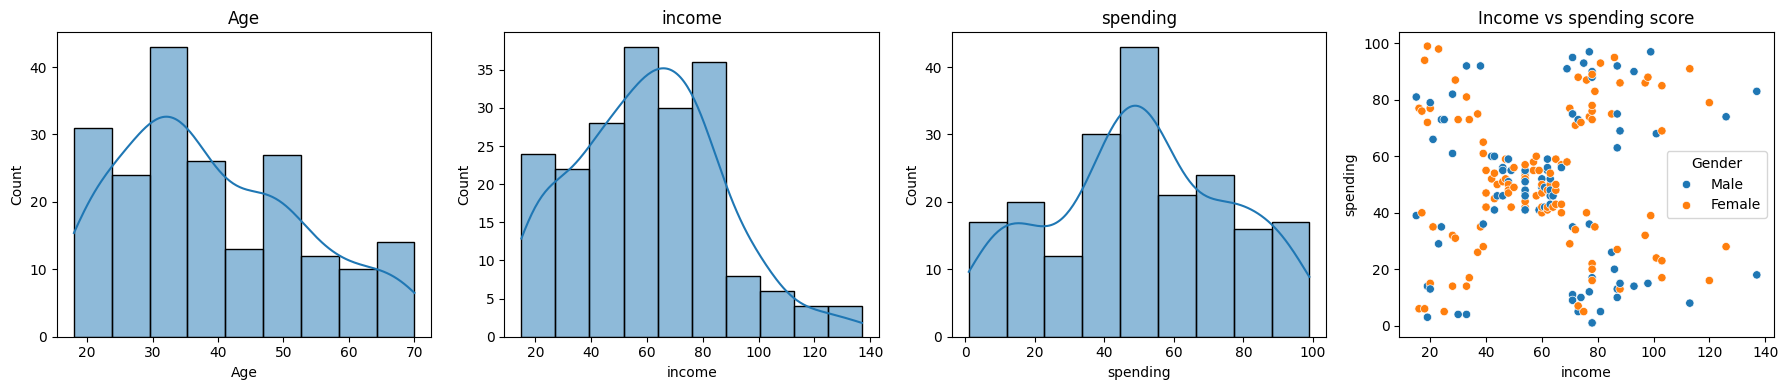

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes[:3], ['Age', 'income', 'spending']):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
sns.scatterplot(data=df, x='income', y='spending', hue='Gender', ax=axes[3])
axes[3].set_title('Income vs spending score')
plt.tight_layout()
plt.show()

**What to notice:** look at the last plot (income against spending score). The dots do **not** form one blob: you can see **separate clumps**. Clustering is meant to find exactly this kind of hidden structure. Gender does not seem to separate the clumps, so we will start with the two columns that show the structure: `income` and `spending`.

## Step 3: Prepare the data

K-Means works with **distances**, so a column with big numbers would dominate a column with small numbers. Income (about 15 to 137) and spending (1 to 100) are on similar scales here, but age (18 to 70) and later other features are not the same, so we get into the habit of **standardizing** (mean 0, spread 1) before clustering. Without it, K-Means (like KNN and SVM) listens mostly to the largest numbers.

In [4]:
from sklearn.preprocessing import StandardScaler

features = ['income', 'spending']
scaler = StandardScaler()
X2 = scaler.fit_transform(df[features])     # a NumPy array: 200 customers x 2 features

print('Scaled data: mean', X2.mean(axis=0).round(2), '| std', X2.std(axis=0).round(2))

Scaled data: mean [-0. -0.] | std [1. 1.]


There is no test set here, so we fit the scaler on all 200 customers. We are describing this group of customers, not predicting for new ones.

## Step 4: K-Means from scratch

Let us implement the four steps ourselves (about 15 lines) for `k = 5`, and watch the centroids move.

Rounds until it stopped moving: 7
Inertia of our model: 98.46 (inertia = total squared distance from every customer to its centre; lower is tighter)


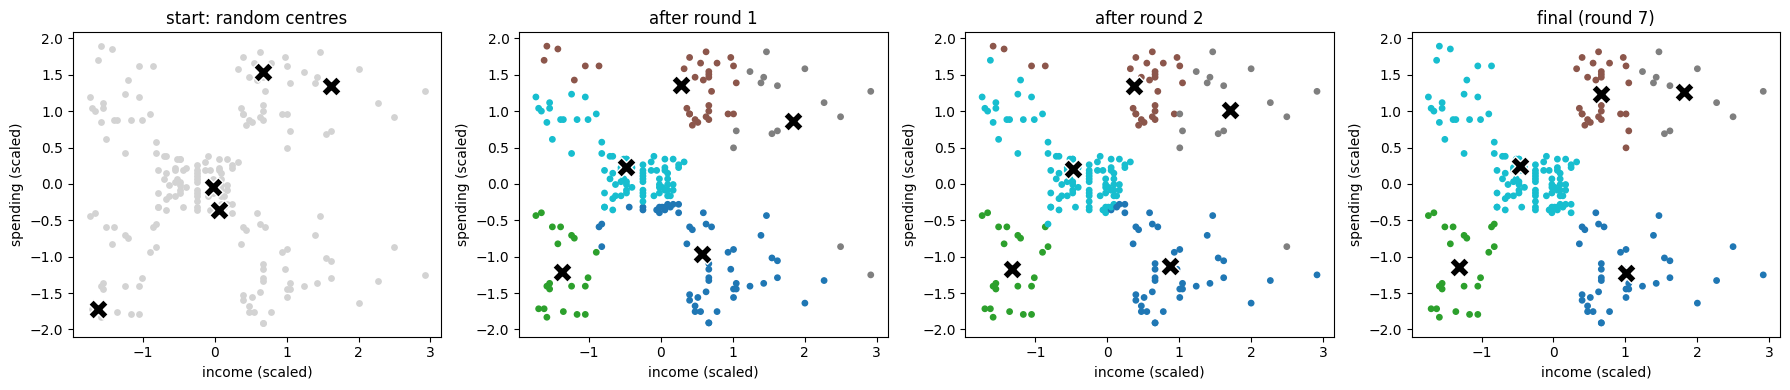

In [5]:
def my_kmeans(X, k, seed=0, max_iter=50):
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), k, replace=False)]            # step 1: k random customers as the first centres
    history = [(centers.copy(), None)]
    for _ in range(max_iter):
        dist = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = dist.argmin(axis=1)                              # step 2: assign each customer to the nearest centre
        new_centers = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centers[j]
                                for j in range(k)])               # step 3: move each centre to the average of its customers
        history.append((new_centers.copy(), labels.copy()))
        if np.allclose(new_centers, centers):                     # step 4: stop when nothing moves any more
            break
        centers = new_centers
    inertia = ((X - centers[labels]) ** 2).sum()
    return labels, centers, inertia, history


labels_s, centers_s, inertia_s, history = my_kmeans(X2, k=5, seed=1)
print('Rounds until it stopped moving:', len(history) - 1)
print('Inertia of our model:', round(inertia_s, 2), '(inertia = total squared distance from every customer to its centre; lower is tighter)')

picks = sorted(set([0, 1, 2, len(history) - 1]))
fig, axes = plt.subplots(1, len(picks), figsize=(4.5 * len(picks), 4))
for ax, i in zip(np.atleast_1d(axes), picks):
    c, lab = history[i]
    if lab is None:
        ax.scatter(X2[:, 0], X2[:, 1], color='lightgray', s=15)
        ax.set_title('start: random centres')
    else:
        ax.scatter(X2[:, 0], X2[:, 1], c=lab, cmap='tab10', s=15)
        ax.set_title(f'after round {i}' if i < len(history) - 1 else f'final (round {i})')
    ax.scatter(c[:, 0], c[:, 1], marker='X', s=200, color='black', edgecolor='white')
    ax.set_xlabel('income (scaled)')
    ax.set_ylabel('spending (scaled)')
plt.tight_layout()
plt.show()

In [6]:
from sklearn.cluster import KMeans

km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X2)
print('scikit-learn inertia (k=5, 10 random starts):', round(km5.inertia_, 2))
print('Our from-scratch inertia                    :', round(inertia_s, 2))

scikit-learn inertia (k=5, 10 random starts): 65.57
Our from-scratch inertia                    : 98.46


**What to notice:** the black crosses (centroids) start at random customers and **slide towards the middle of the clumps**, while the colours settle. Our version and scikit-learn's should be close or equal. If ours is higher (it can be much higher), it got an **unlucky random start** and settled in a poorer solution (a *local minimum*). That is exactly the problem that `n_init` (many restarts, keep the best) and `k-means++` (a smarter start) solve in scikit-learn. We come back to it in Step 8.

## Step 5: Choose k

K-Means needs `k` in advance. Two common tools:

- **Elbow method:** plot the inertia for several `k`. It always drops as `k` grows (more centres, shorter distances), but the drop becomes small once you have enough clusters. Look for the **bend (elbow)**.
- **Silhouette score:** for every customer, compares the distance to its own cluster with the distance to the nearest other cluster. It goes from -1 to 1; **higher is better**, and values near 0 mean overlapping clusters.

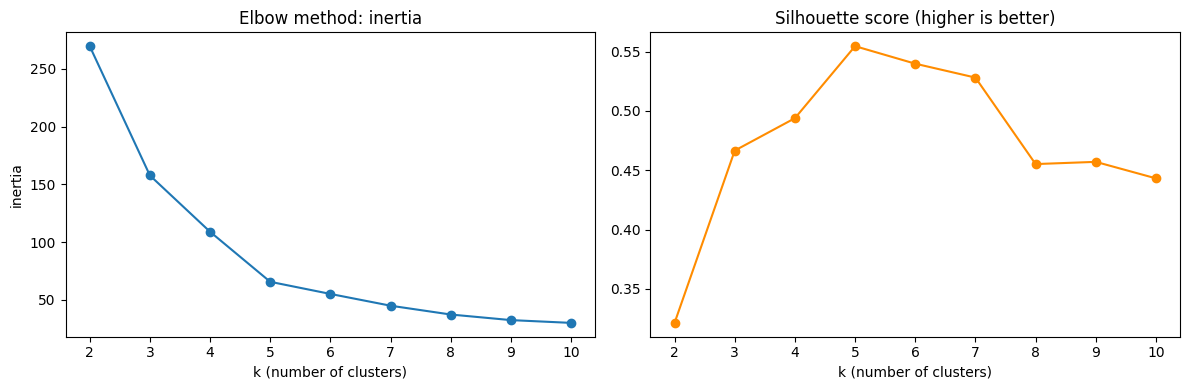

 k  inertia  silhouette
 2  269.691       0.321
 3  157.704       0.467
 4  108.921       0.494
 5   65.568       0.555
 6   55.057       0.540
 7   44.865       0.528
 8   37.228       0.455
 9   32.392       0.457
10   29.982       0.443

k with the best silhouette score: 5


In [7]:
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X2)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(X2, m.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, marker='o')
axes[0].set_title('Elbow method: inertia')
axes[0].set_xlabel('k (number of clusters)')
axes[0].set_ylabel('inertia')
axes[1].plot(list(ks), sils, marker='o', color='darkorange')
axes[1].set_title('Silhouette score (higher is better)')
axes[1].set_xlabel('k (number of clusters)')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'k': list(ks), 'inertia': inertias, 'silhouette': sils}).round(3).to_string(index=False))
best_k = list(ks)[int(np.argmax(sils))]
print()
print('k with the best silhouette score:', best_k)

**How to read this:** on the left, find where the curve stops dropping steeply (the elbow). On the right, find the highest point. On this data both tools usually point to **about 5 clusters**, which matches the 5 clumps we saw in the scatter plot. Real data is often less clear-cut, so use the two methods together with common sense and the business need. From now on we use the `k` with the best silhouette score (`best_k`).

## Step 6: The final clusters

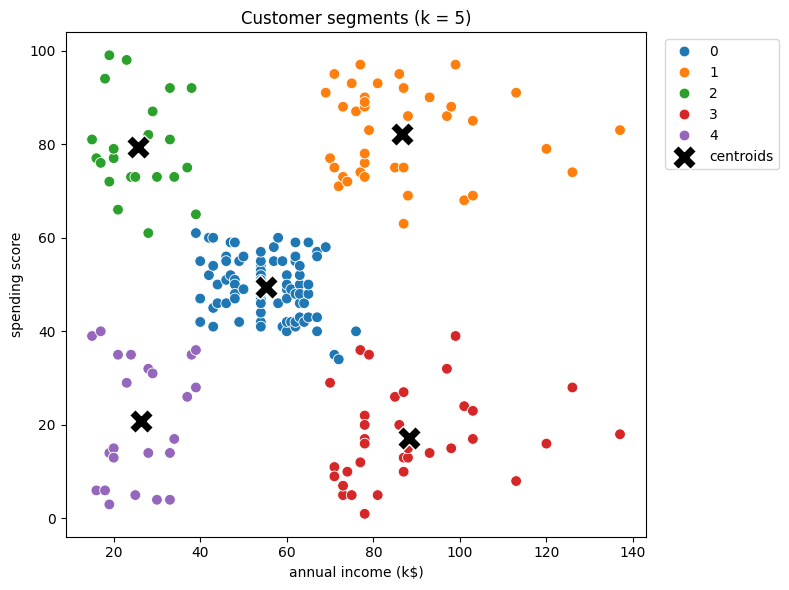

Silhouette score: 0.555


In [8]:
final = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X2)
df['cluster'] = final.labels_
centers = scaler.inverse_transform(final.cluster_centers_)       # centroids back in the original units

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='income', y='spending', hue='cluster', palette='tab10', s=60)
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=300, color='black', edgecolor='white', label='centroids')
plt.title(f'Customer segments (k = {best_k})')
plt.xlabel('annual income (k$)')
plt.ylabel('spending score')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print('Silhouette score:', round(silhouette_score(X2, final.labels_), 3))

**What to notice:** each colour is one segment, and the black crosses are the segment centres. Clusters are chosen so that customers inside a group are close to each other and far from the other groups.

## Step 7: Profile and name the clusters

A cluster number means nothing to a marketer. We profile each cluster (average age, income and spending, and its size), and give it a descriptive name by comparing its centre with the overall median.

         customers  avg_age  avg_income  avg_spending  share_female  share_of_customers                        name
cluster                                                                                                            
0               81    42.72       55.30         49.52          0.59                0.40    mid income, mid spending
1               39    32.69       86.54         82.13          0.54                0.20  high income, high spending
2               22    25.27       25.73         79.36          0.59                0.11   low income, high spending
3               35    41.11       88.20         17.11          0.46                0.18   high income, low spending
4               23    45.22       26.30         20.91          0.61                0.12    low income, low spending


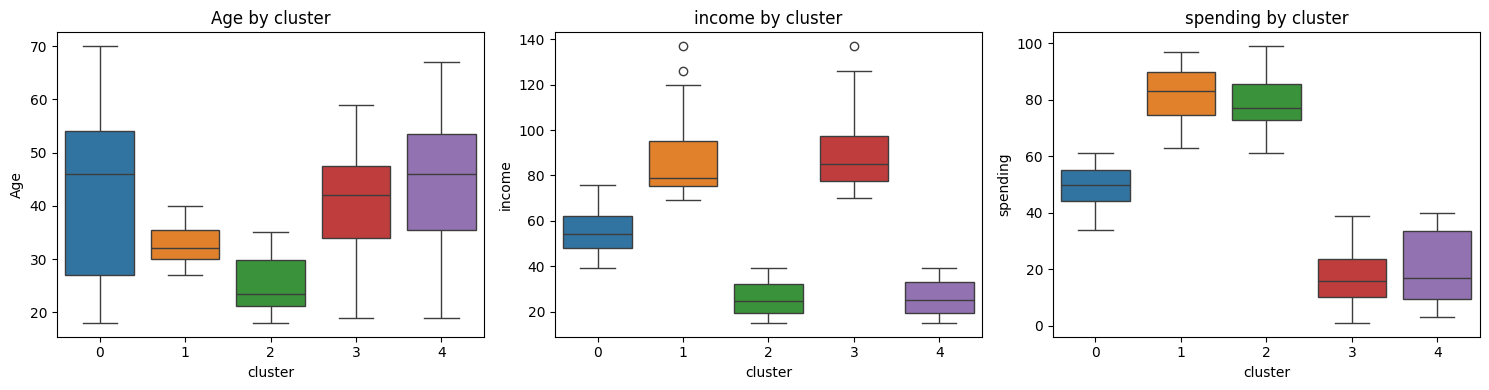

In [9]:
profile = df.groupby('cluster').agg(customers=('CustomerID', 'size'),
                                    avg_age=('Age', 'mean'),
                                    avg_income=('income', 'mean'),
                                    avg_spending=('spending', 'mean'),
                                    share_female=('Gender', lambda s: (s == 'Female').mean()))
profile['share_of_customers'] = profile['customers'] / len(df)

inc_med, sp_med = df['income'].median(), df['spending'].median()


def name_cluster(row):
    inc = 'high income' if row['avg_income'] > inc_med + 10 else ('low income' if row['avg_income'] < inc_med - 10 else 'mid income')
    sp = 'high spending' if row['avg_spending'] > sp_med + 10 else ('low spending' if row['avg_spending'] < sp_med - 10 else 'mid spending')
    return f'{inc}, {sp}'


profile['name'] = profile.apply(name_cluster, axis=1)
print(profile.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Age', 'income', 'spending']):
    sns.boxplot(data=df, x='cluster', y=col, hue='cluster', palette='tab10', legend=False, ax=ax)
    ax.set_title(col + ' by cluster')
plt.tight_layout()
plt.show()

**What to notice:** each row is a customer segment with a plain-English name. Typical segments in this data set include "high income, high spending" (the best customers to keep happy), "high income, low spending" (rich but not spending here, a chance for targeted offers), and "low income, high spending" (enthusiastic shoppers, maybe attracted by deals). Check the names against **your** table, because the cluster numbers change from run to run, but the groups should be the same.

**Business ideas:** loyalty perks for the big spenders, special campaigns to wake up the rich low spenders, discounts for the budget-conscious, and so on. That is the real value of clustering: it turns raw numbers into **actions**.

## Step 8: How stable are the clusters?

K-Means starts from random centres, so different starts can end differently. We run it 10 times **with a single random start each** and see how much the result varies. We measure it with the **Adjusted Rand Index (ARI)**: 1.0 means the same grouping as the reference, and 0 means a random grouping.

In [10]:
from sklearn.metrics import adjusted_rand_score

rows = []
for seed in range(10):
    m = KMeans(n_clusters=best_k, init='random', n_init=1, random_state=seed).fit(X2)
    rows.append({'run': seed, 'inertia': m.inertia_, 'ARI vs final model': adjusted_rand_score(final.labels_, m.labels_)})
runs = pd.DataFrame(rows)
print('Single random start each time:')
print(runs.round(3).to_string(index=False))
print()
print(f'Best and worst inertia: {runs.inertia.min():.2f} and {runs.inertia.max():.2f}')
print(f'Inertia of our final model (k-means++ and 10 starts): {final.inertia_:.2f}')
print(f'Runs that reproduce the final grouping exactly: {(runs["ARI vs final model"] > 0.999).sum()} of 10')

Single random start each time:
 run  inertia  ARI vs final model
   0   65.568               1.000
   1   65.568               1.000
   2   98.764               0.703
   3   65.568               1.000
   4  132.996               0.501
   5   65.568               1.000
   6   65.579               0.985
   7   99.185               0.714
   8  111.981               0.723
   9   65.579               0.985

Best and worst inertia: 65.57 and 133.00
Inertia of our final model (k-means++ and 10 starts): 65.57
Runs that reproduce the final grouping exactly: 4 of 10


**How to read this:** if some runs have a **higher inertia** and a lower ARI, they got stuck in a worse solution because of an unlucky start. This is why scikit-learn uses `init='k-means++'` (spreads the first centres apart) and `n_init=10` (runs 10 times, keeps the best) by default. On clean, well-separated data like this one most runs agree, but on messier data the difference can be large. **Always use several starts.**

## Step 9: What if we use more features?

So far we used two features. What happens if we also give K-Means the customer's **age** and **gender**? We encode gender as 0/1, scale everything, find the best `k` again, and compare. Since we can no longer plot 4 dimensions, we squash them to 2D with **PCA** for the picture.

 k  silhouette
 2       0.252
 3       0.260
 4       0.298
 5       0.304
 6       0.331
 7       0.357
 8       0.388
 9       0.403
10       0.421

Best k with 4 features: 10, silhouette 0.421
Best silhouette with 2 features: 0.555
Agreement between the 2-feature and the 4-feature grouping (ARI): 0.369


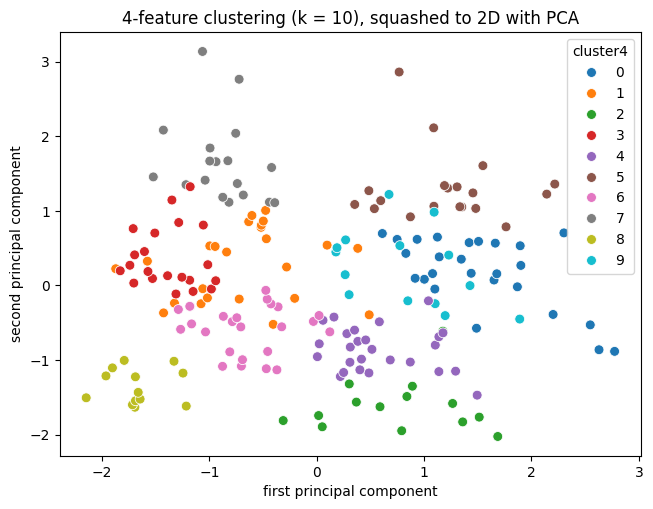

            Age  income  spending  gender_num
cluster4                                     
0         58.85   48.69     39.85        0.00
1         25.25   41.25     60.92        0.00
2         41.21   26.07     20.14        0.93
3         32.19   86.05     81.67        1.00
4         54.15   54.23     48.96        1.00
5         38.47   85.89     14.21        0.00
6         27.96   57.36     47.12        1.00
7         33.28   87.11     82.67        0.00
8         25.46   25.69     80.54        1.00
9         43.79   93.29     20.64        1.00


In [11]:
from sklearn.decomposition import PCA

df['gender_num'] = (df['Gender'] == 'Female').astype(int)
cols_more = ['Age', 'income', 'spending', 'gender_num']
X4 = StandardScaler().fit_transform(df[cols_more])

rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X4)
    rows.append({'k': k, 'silhouette': silhouette_score(X4, m.labels_)})
sil4 = pd.DataFrame(rows)
print(sil4.round(3).to_string(index=False))
k4 = int(sil4.loc[sil4['silhouette'].idxmax(), 'k'])
km4 = KMeans(n_clusters=k4, n_init=10, random_state=42).fit(X4)
df['cluster4'] = km4.labels_
print()
print(f'Best k with 4 features: {k4}, silhouette {sil4["silhouette"].max():.3f}')
print(f'Best silhouette with 2 features: {max(sils):.3f}')
print('Agreement between the 2-feature and the 4-feature grouping (ARI):',
      round(adjusted_rand_score(df['cluster'], df['cluster4']), 3))

pcs = PCA(n_components=2).fit_transform(X4)
plt.figure(figsize=(7.5, 5.5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df['cluster4'], palette='tab10', s=50)
plt.title(f'4-feature clustering (k = {k4}), squashed to 2D with PCA')
plt.xlabel('first principal component')
plt.ylabel('second principal component')
plt.show()

print(df.groupby('cluster4')[['Age', 'income', 'spending', 'gender_num']].mean().round(2).to_string())

**What to notice:** adding features usually makes the clusters **less clean**: the silhouette score tends to drop, because age and gender do not create clear clumps the way income and spending do. Compare the two silhouette scores and the ARI. If the best `k` printed above is at the very edge of the range (10), be suspicious: a 0/1 column like gender lets the algorithm split the data into many small groups, and the silhouette score keeps rewarding that. More features is not automatically better in clustering. **Choose the features that matter for the question you are asking**, here: "how much do customers earn and how much do they spend?". If age matters for your campaign, then the age-based groups are useful in their own right.

## Step 10: Other clustering algorithms

K-Means is not the only choice. We try three others on the same two scaled features and compare them with K-Means using the ARI (how similar are the groupings?) and the silhouette score.

- **Hierarchical (Agglomerative, Ward):** starts with every customer alone and repeatedly merges the closest groups.
- **Gaussian Mixture Model (GMM):** assumes each cluster is a bell-shaped blob, and gives **soft** (probabilistic) membership.
- **DBSCAN:** finds **dense regions** of any shape and labels sparse points as **noise**. It needs no `k`, but needs a neighbourhood size `eps`.

          algorithm  clusters found  noise points  silhouette  ARI vs K-Means
            K-Means               5             0       0.555           1.000
Hierarchical (Ward)               5             0       0.554           0.942
   Gaussian mixture               5             0       0.554           0.956
   DBSCAN (eps=0.4)               4            15       0.478           0.568


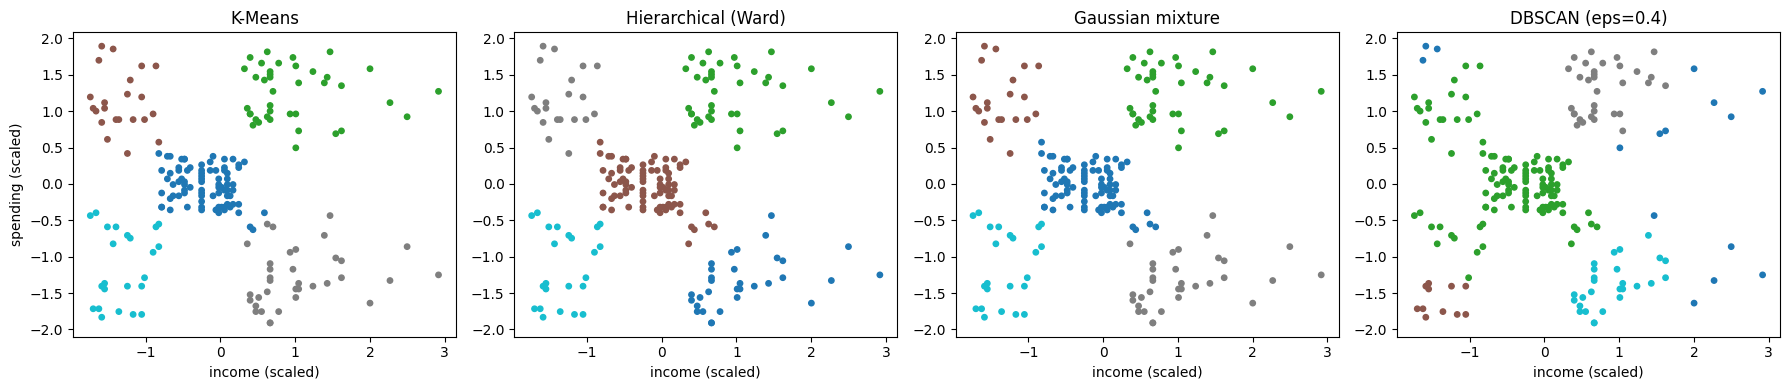

In [12]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture

results = {
    'K-Means': final.labels_,
    'Hierarchical (Ward)': AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X2),
    'Gaussian mixture': GaussianMixture(n_components=best_k, n_init=5, random_state=42).fit_predict(X2),
    'DBSCAN (eps=0.4)': DBSCAN(eps=0.4, min_samples=5).fit_predict(X2),
}

rows = []
for name, lab in results.items():
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    noise = int((lab == -1).sum())
    ok = lab != -1
    sil = silhouette_score(X2[ok], lab[ok]) if n_clusters > 1 and ok.sum() > n_clusters else np.nan
    rows.append({'algorithm': name, 'clusters found': n_clusters, 'noise points': noise,
                 'silhouette': sil, 'ARI vs K-Means': adjusted_rand_score(results['K-Means'], lab)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, lab) in zip(axes, results.items()):
    ax.scatter(X2[:, 0], X2[:, 1], c=lab, cmap='tab10', s=15)
    ax.set_title(name)
    ax.set_xlabel('income (scaled)')
axes[0].set_ylabel('spending (scaled)')
plt.tight_layout()
plt.show()

**What to notice:** on clean, round clumps like these, K-Means, hierarchical clustering and the Gaussian mixture usually agree almost completely (ARI close to 1). DBSCAN depends on `eps`: a different value can give more clusters, fewer clusters or many noise points, so try changing it. (In DBSCAN, the noise points are labelled -1 and are drawn in their own colour.) K-Means is fast and simple but assumes **roughly round clusters of similar size**. When clusters are curved, very different in size or have outliers, the other algorithms can do better.

## Step 11: Assign a new customer to a segment

A new customer arrives with an income of 85k and a spending score of 20. Which segment do they belong to?

In [13]:
new = pd.DataFrame([{'income': 85, 'spending': 20}])
cluster_id = int(final.predict(scaler.transform(new))[0])
print('New customer:', new.iloc[0].to_dict())
print('Assigned to cluster', cluster_id, '->', profile.loc[cluster_id, 'name'])

# distance to every centre, so you can see how clear-cut the assignment is
dist = np.linalg.norm(final.cluster_centers_ - scaler.transform(new), axis=1)
print()
print('Distance (in scaled units) to each cluster centre:')
print(pd.Series(dist.round(2), name='distance').rename_axis('cluster').to_string())

New customer: {'income': 85, 'spending': 20}
Assigned to cluster 3 -> high income, low spending

Distance (in scaled units) to each cluster centre:
cluster
0    1.61
1    2.41
2    3.23
3    0.17
4    2.24


**Try it:** change the income and spending values and see which segment you land in. A customer that sits **between two clusters** has two similar distances: that assignment is less certain (a Gaussian mixture would give you a probability instead).

## Practice ideas

1. In Step 6, force `k = 3` and `k = 7`. Do the segments still make business sense?
2. In Step 3, remove the scaling and compare the clusters when you also include age (the scale of each feature then matters more).
3. Try `MiniBatchKMeans`, which is faster on big data, and compare its inertia with `KMeans`.
4. In Step 10, change DBSCAN's `eps` to 0.3, 0.5 and 0.6 and watch how the number of clusters and noise points change.
5. Draw a **dendrogram** of the hierarchical clustering with `scipy.cluster.hierarchy`.
6. Use the **silhouette plot** per cluster (`sklearn.metrics.silhouette_samples`) to see which customers fit their cluster badly.
7. Use clustering for **image colour compression**: cluster the pixels of a photo into 8 colours and rebuild the picture.